## Import Leone Data, Fit, and Plot

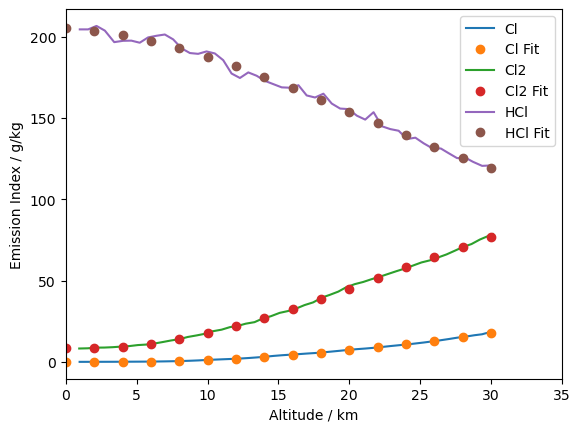

In [19]:
# Import data from csv
import numpy as np
import matplotlib.pyplot as plt
import sys
from scipy.optimize import curve_fit

chlorine_file = np.genfromtxt("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/Chlorine_Leone.csv",
                    delimiter=",",skip_header=1)

alt_cl  = chlorine_file[:,0]
ei_cl   = chlorine_file[:,1]
alt_cl2 = chlorine_file[:,2]
ei_cl2  = chlorine_file[:,3]
alt_hcl = chlorine_file[:,4]
ei_hcl  = chlorine_file[:,5]

# Fit a polynomial to each Leone profile
xn = np.arange(0,32,2)
yn_cl  = np.poly1d(np.polyfit(alt_cl[~np.isnan(alt_cl)],ei_cl[~np.isnan(ei_cl)],3))
yn_cl2 = np.poly1d(np.polyfit(alt_cl2[~np.isnan(alt_cl2)],ei_cl2[~np.isnan(ei_cl2)],3))
yn_hcl = np.poly1d(np.polyfit(alt_hcl[~np.isnan(alt_hcl)],ei_hcl[~np.isnan(ei_hcl)],3))

plt.plot(alt_cl,ei_cl,label="Cl")
plt.plot(xn,yn_cl(xn),'o',label="Cl Fit")
plt.plot(alt_cl2,ei_cl2,label="Cl2")
plt.plot(xn,yn_cl2(xn),'o',label="Cl2 Fit")
plt.plot(alt_hcl,ei_hcl,label="HCl")
plt.plot(xn,yn_hcl(xn),'o',label="HCl Fit")
plt.xlim(0,35)
#plt.ylim(0,100)
plt.xlabel("Altitude / km")
plt.ylabel("Emission Index / g/kg")
plt.legend()

## Add Gomberg, Zittel, Denison Data

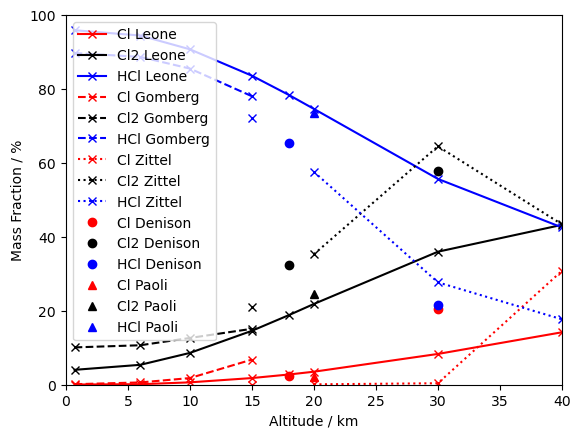

In [20]:
alt_lit = np.asarray([0.7,6,10,15,18,20,30,40])
mass_frac_cl = np.zeros_like(alt_lit)
mass_frac_cl2 = np.zeros_like(alt_lit)
mass_frac_hcl = np.zeros_like(alt_lit)
for count, alt in enumerate(alt_lit):
    mass_frac_cl[count] = yn_cl(alt)/(yn_cl(alt)+yn_cl2(alt)+yn_hcl(alt)) * 100
    mass_frac_cl2[count] = yn_cl2(alt)/(yn_cl(alt)+yn_cl2(alt)+yn_hcl(alt)) * 100
    mass_frac_hcl[count] = yn_hcl(alt)/(yn_cl(alt)+yn_cl2(alt)+yn_hcl(alt)) * 100

denison_total_18 = 2.55 + 36.57 + 73.76
denison_total_30 = 20.60 + 21.54 + 57.88
paoli_cl_mass = 0.02 * 35.453
paoli_cl2_mass = 0.25 * 35.453 
paoli_hcl_mass = 0.73 * (35.453 + 1.008)
paoli_total_20 = paoli_cl_mass + paoli_cl2_mass + paoli_hcl_mass

gomberg_hcl = [89.75,88.69,85.54,78.06,np.nan,np.nan,np.nan,np.nan]
gomberg_cl2 = [10.1,10.68,12.65,15.13,np.nan,np.nan,np.nan,np.nan]
gomberg_cl  = [0.14,0.62,1.8,6.8,np.nan,np.nan,np.nan,np.nan]
zittel_cl   = [np.nan,np.nan,np.nan,0.01,np.nan,0.1,0.4,30.8]
zittel_cl2  = [np.nan,np.nan,np.nan,21,np.nan,35.3,64.5,43.4]
zittel_hcl  = [np.nan,np.nan,np.nan,72.2,np.nan,57.6,27.7,17.7]
denison_hcl = [np.nan,np.nan,np.nan,np.nan,73.76/denison_total_18*100,np.nan,21.54/denison_total_30*100,np.nan]
denison_cl2 = [np.nan,np.nan,np.nan,np.nan,36.57/denison_total_18*100,np.nan,57.88/denison_total_30*100,np.nan]
denison_cl  = [np.nan,np.nan,np.nan,np.nan,2.55/denison_total_18*100,np.nan,20.60/denison_total_30*100,np.nan]
paoli_hcl = [np.nan,np.nan,np.nan,np.nan,np.nan,paoli_hcl_mass/paoli_total_20*100,np.nan,np.nan]
paoli_cl2 = [np.nan,np.nan,np.nan,np.nan,np.nan,paoli_cl2_mass/paoli_total_20*100,np.nan,np.nan]
paoli_cl  = [np.nan,np.nan,np.nan,np.nan,np.nan,paoli_cl_mass/paoli_total_20*100,np.nan,np.nan]

plt.plot(alt_lit,mass_frac_cl,'-xr',label="Cl Leone")
plt.plot(alt_lit,mass_frac_cl2,'-xk',label="Cl2 Leone")
plt.plot(alt_lit,mass_frac_hcl,'-xb',label="HCl Leone")
plt.plot(alt_lit,gomberg_cl,'--xr',label="Cl Gomberg")
plt.plot(alt_lit,gomberg_cl2,'--xk',label="Cl2 Gomberg")
plt.plot(alt_lit,gomberg_hcl,'--xb',label="HCl Gomberg")
plt.plot(alt_lit,zittel_cl,':xr',label="Cl Zittel")
plt.plot(alt_lit,zittel_cl2,':xk',label="Cl2 Zittel")
plt.plot(alt_lit,zittel_hcl,':xb',label="HCl Zittel")
plt.plot(alt_lit,denison_cl,'or',label="Cl Denison")
plt.plot(alt_lit,denison_cl2,'ok',label="Cl2 Denison")
plt.plot(alt_lit,denison_hcl,'ob',label="HCl Denison")
plt.plot(alt_lit,paoli_cl,'^r',label="Cl Paoli")
plt.plot(alt_lit,paoli_cl2,'^k',label="Cl2 Paoli")
plt.plot(alt_lit,paoli_hcl,'^b',label="HCl Paoli")
plt.xlim(0,40)
plt.ylim(0,100)
plt.xlabel("Altitude / km")
plt.ylabel("Mass Fraction / %")
plt.legend()

# Create an average of all of the data

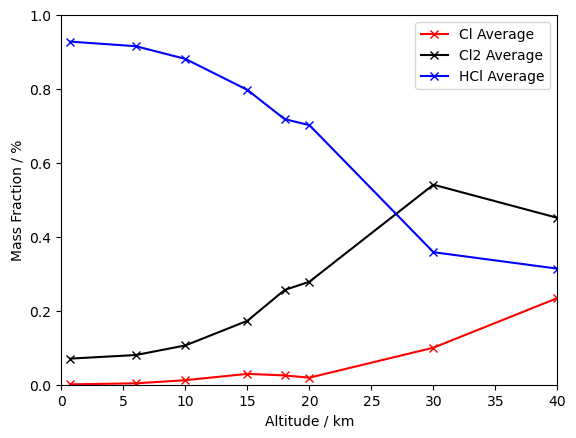

In [21]:
mass_frac_cl_average = np.zeros_like(alt_lit)
mass_frac_cl2_average = np.zeros_like(alt_lit)
mass_frac_hcl_average = np.zeros_like(alt_lit)
for count, alt in enumerate(alt_lit):
    mass_frac_cl_average[count] = np.nanmean([mass_frac_cl[count],gomberg_cl[count],zittel_cl[count],denison_cl[count],paoli_cl[count]])
    mass_frac_cl2_average[count] = np.nanmean([mass_frac_cl2[count],gomberg_cl2[count],zittel_cl2[count],denison_cl2[count],paoli_cl2[count]])
    mass_frac_hcl_average[count] = np.nanmean([mass_frac_hcl[count],gomberg_hcl[count],zittel_hcl[count],denison_hcl[count],paoli_hcl[count]])
    total_mass_frac = (mass_frac_cl_average[count] + mass_frac_cl2_average[count] + mass_frac_hcl_average[count])
    mass_frac_cl_average[count] = mass_frac_cl_average[count] / total_mass_frac * 1
    mass_frac_cl2_average[count] = mass_frac_cl2_average[count] / total_mass_frac * 1
    mass_frac_hcl_average[count] = mass_frac_hcl_average[count] / total_mass_frac * 1    

plt.plot(alt_lit,mass_frac_cl_average,'-xr',label="Cl Average")
plt.plot(alt_lit,mass_frac_cl2_average,'-xk',label="Cl2 Average")
plt.plot(alt_lit,mass_frac_hcl_average,'-xb',label="HCl Average")
plt.xlim(0,40)
plt.ylim(0,1)
plt.xlabel("Altitude / km")
plt.ylabel("Mass Fraction / %")
plt.legend()

# Plot as a function of atmospheric pressure

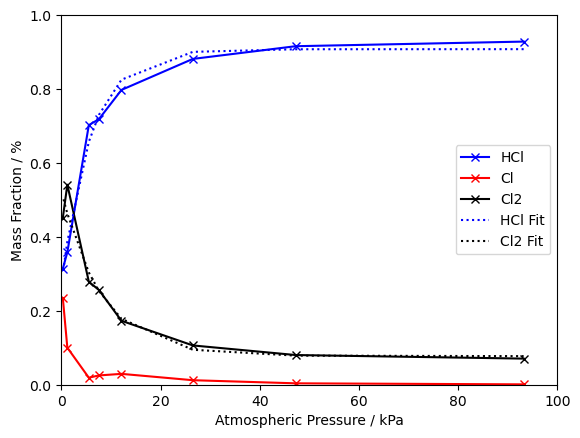

In [22]:
sys.path.append('/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/')
from tables import print_pressures

alt, temp, pressure, delta = print_pressures(alt_lit)

# Fit an exponential curve to mass fraction vs. atmospheric pressure
def test(x, a, b, c, d):
    return a * np.exp(-b*x+c) + d

param_hcl, _ = curve_fit(test, pressure[::-1]*1e-3, 1-mass_frac_hcl_average[::-1])
param_cl2, _  = curve_fit(test, pressure[::-1]*1e-3, mass_frac_cl2_average[::-1])

plt.plot(pressure*1e-3,mass_frac_hcl_average,'-xb',label="HCl") 
plt.plot(pressure*1e-3,mass_frac_cl_average,'-xr',label="Cl") 
plt.plot(pressure*1e-3,mass_frac_cl2_average,'-xk',label="Cl2") 
plt.plot(pressure*1e-3,1-test(pressure*1e-3, param_hcl[0], param_hcl[1], param_hcl[2], param_hcl[3]),':b',label="HCl Fit") 
plt.plot(pressure*1e-3,test(pressure*1e-3, param_cl2[0], param_cl2[1], param_cl2[2], param_cl2[3]),':k',label="Cl2 Fit")  
plt.xlim(0,100)
plt.ylim(0,1)
plt.xlabel("Atmospheric Pressure / kPa")
plt.ylabel("Mass Fraction / %")
plt.legend()


## Extend the fits over 0-80km

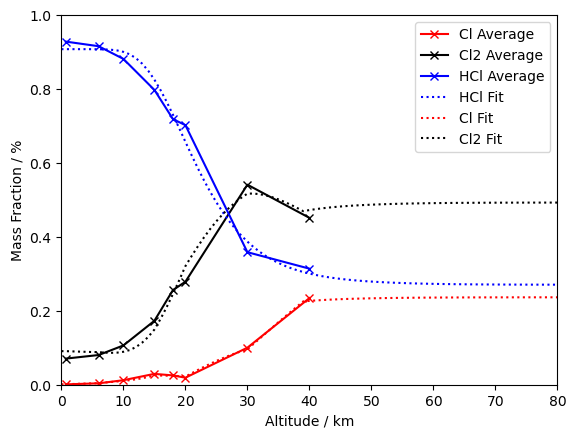

In [23]:
# Extend the relationship from 0-80 km.
alt_extended, temp_extended, pressure_extended, delta_extended = print_pressures(np.arange(81,dtype=float))
mass_frac_extended_cl_cl2 = test(pressure_extended*1e-3, param_hcl[0], param_hcl[1], param_hcl[2], param_hcl[3])

mass_frac_cl = np.interp(alt_extended,alt_lit,mass_frac_cl_average)
mass_frac_cl2 = np.interp(alt_extended,alt_lit,mass_frac_cl2_average)

for count, altitude in enumerate(alt_extended):
    if altitude < 40:
        cl_frac = mass_frac_cl[count] / (mass_frac_cl[count] + mass_frac_cl2[count])
        cl2_frac = mass_frac_cl2[count] / (mass_frac_cl[count] + mass_frac_cl2[count])
    mass_frac_cl[count]  = mass_frac_extended_cl_cl2[count] * cl_frac
    mass_frac_cl2[count] = mass_frac_extended_cl_cl2[count] * cl2_frac
    
plt.plot(alt_lit,mass_frac_cl_average,'-xr',label="Cl Average")
plt.plot(alt_lit,mass_frac_cl2_average,'-xk',label="Cl2 Average")
plt.plot(alt_lit,mass_frac_hcl_average,'-xb',label="HCl Average")
plt.plot(alt_extended,1-mass_frac_extended_cl_cl2,':b',label="HCl Fit")
plt.plot(alt_extended,mass_frac_cl,':r',label="Cl Fit")
plt.plot(alt_extended,mass_frac_cl2,':k',label="Cl2 Fit")
plt.xlim(0,80)
plt.ylim(0,1)
plt.xlabel("Altitude / km")
plt.ylabel("Mass Fraction / %")
plt.legend()

## Output for main script

In [24]:
import pandas as pd
param_hcl = np.append(param_hcl,[0,0,0,0]) 
df = pd.DataFrame(
    {
        "Alt": alt_lit,
        "HCl": param_hcl,
        "Cl2": mass_frac_cl2_average,
        "Cl":  mass_frac_cl_average,
    }
)
df.to_csv("/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Databases/Chlorine_PEI.csv", float_format='%.3f')